# TP : un Transformer de zéro, puis le fine-tuning de BERT

# Partie 1 : un Transformer de zéro

## 1.0 Repérer les critiques négatives

Une plateforme de streaming veut repérer les critiques négatives de films pour les transmettre au service client. Elle n'a
étiqueté que quelques centaines de phrases (positive ou négative).

Les phrases viennent de SST-2 (critiques de films, en anglais). Il faut Internet pour télécharger les phrases (1 Mo) et, en
partie 2, un modèle (115 Mo, une seule fois).

In [ ]:
# pip install "keras==3.15.1" "keras-hub==0.33.0" "torch==2.11.0" "numpy==2.4.6" "matplotlib==3.11.2"
import os
os.environ["KERAS_BACKEND"] = "torch"

import json
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import keras
import keras_hub
from keras import layers, ops

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
keras.utils.set_random_seed(0)

PRESET = "bert_small_en_uncased"
SEQ_LEN = 48
EPOCHS = 4

In [ ]:
def read(name):
    path = keras.utils.get_file(f"sst2_{name}.jsonl", f"https://huggingface.co/datasets/SetFit/sst2/resolve/main/{name}.jsonl")
    with open(path, encoding="utf-8") as f:
        rows = [json.loads(line) for line in f]
    return [row["text"] for row in rows], np.array([row["label"] for row in rows])


train_texts, train_labels = read("train")
val_texts, val_labels = read("dev")
majority = max(val_labels.mean(), 1 - val_labels.mean())

for text, label in list(zip(train_texts, train_labels))[:3]:
    print(f"{'positive' if label else 'negative':9s} {text}")
print(f"{len(train_texts)} phrases d'entraînement, {len(val_texts)} de validation ; la classe majoritaire fait {majority:.1%} en validation")

## 1.1 Les jetons

Un Transformer lit des **jetons**, des morceaux de mots tirés d'un vocabulaire fixe. On emprunte le découpage de BERT (un modèle
utilisé en partie 2), mais aucun de ses poids. Trois jetons sont spéciaux : `[CLS]` ouvre la phrase, `[SEP]` la ferme, `[PAD]`
complète jusqu'à `SEQ_LEN` jetons. Le préprocesseur rend `token_ids`, `padding_mask` (1 sur les vrais jetons) et `segment_ids`
(un numéro de phrase, ici toujours 0).

**Q1.** Pour classer la phrase, le modèle ne regardera que le vecteur de sortie du jeton `[CLS]`, qui n'est aucun mot de la
phrase. Comment ce vecteur peut-il porter le sens de toute la phrase ?

**Votre réponse :**




In [ ]:
preprocessor = keras_hub.models.BertTextClassifierPreprocessor.from_preset(PRESET, sequence_length=SEQ_LEN)
tokenizer = preprocessor.tokenizer
VOCAB_SIZE = tokenizer.vocabulary_size()

# TODO: apply the preprocessor to the training sentences, then to the validation sentences; each result is a dict
# of three arrays (token_ids, padding_mask, segment_ids), to keep as numpy arrays
train_inputs = ...
val_inputs = ...

length = train_inputs["padding_mask"][0].sum()
print([tokenizer.id_to_token(int(i)) for i in train_inputs["token_ids"][0][:length]])
assert set(train_inputs) == {"token_ids", "padding_mask", "segment_ids"}
assert train_inputs["token_ids"].shape == (len(train_texts), SEQ_LEN) and val_inputs["token_ids"].shape == (len(val_texts), SEQ_LEN)

## 1.2 Embeddings et positions

Le modèle ne peut rien calculer sur des numéros de jetons. La première couche, fournie, transforme chaque numéro en un vecteur de
$d$ nombres en additionnant deux vecteurs :

1. l'**embedding du jeton** : une table de `VOCAB_SIZE` lignes et $d$ colonnes. Le jeton numéro $i$ reçoit la ligne $i$, la même
   partout où il apparaît ;
2. l'**embedding de la position** : une seconde table, de `SEQ_LEN` lignes et $d$ colonnes. Le jeton placé en position $p$ reçoit
   en plus la ligne $p$.

Les nombres des deux tables sont des poids : tirés au hasard au départ, puis appris à l'entraînement comme les autres.

La seconde table est nécessaire parce que l'auto-attention ne voit pas l'ordre des jetons. Sans elle, « good , not bad » et
« bad , not good », qui contiennent les mêmes jetons, donneraient le même résultat. Avec elle, `good` en tête de phrase et `good`
en fin de phrase n'ont plus le même vecteur.

In [ ]:
class TokenAndPosition(layers.Layer):
    """The embedding of each token plus a learned embedding of its position."""

    def __init__(self, vocab_size, length, d, **kwargs):
        super().__init__(**kwargs)
        self.length = length
        self.token = layers.Embedding(vocab_size, d)  # one row per token of the vocabulary
        self.position = layers.Embedding(length, d)   # one row per position

    def call(self, token_ids):                        # token_ids: (sentences, length), integers
        positions = ops.arange(self.length)           # 0, 1, ..., length - 1
        return self.token(token_ids) + self.position(positions)  # (sentences, length, d)


embed = TokenAndPosition(VOCAB_SIZE, SEQ_LEN, 128)
two_sentences = train_inputs["token_ids"][:2]
print(f"entrée {two_sentences.shape}  ->  sortie {tuple(embed(two_sentences).shape)}")

## 1.3 L'architecture à coder

À gauche, le modèle complet ; à droite, le contenu d'un bloc encodeur. La couche grise est celle de la section précédente. Entre les
couches figure la forme des tableaux, ici avec $d = 128$.

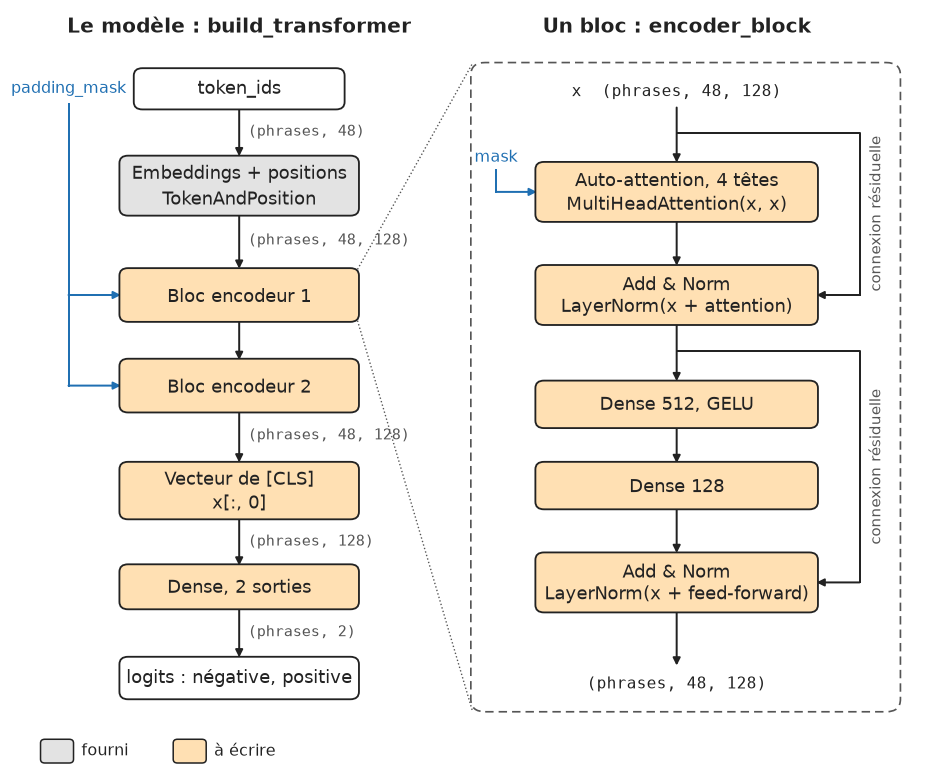

Le classifieur ne lit que le vecteur du premier jeton, `[CLS]`, et rend un score par classe : des **logits**, pas des
probabilités.

## 1.4 Le bloc encodeur

La partie droite du schéma. La sortie a la même forme que l'entrée, ce qui permet d'empiler les blocs. L'activation entre les deux
couches denses est GELU, et la première a `d_ff` unités.

**Q2.** Les phrases sont complétées par des `[PAD]` jusqu'à `SEQ_LEN` jetons. Que se passerait-il avec une auto-attention sans
masque ?

**Votre réponse :**




In [ ]:
def gelu(x):
    """The activation of the feed-forward layers."""
    return keras.activations.gelu(x, approximate=True)


def encoder_block(x, mask, heads, d, d_ff):
    """Self-attention, Add & Norm, feed-forward network, Add & Norm. `mask` (batch, 1, length) is True on real tokens."""
    # TODO: layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads) called on (x, x) with attention_mask=mask, added to x
    # and normalized by layers.LayerNormalization(epsilon=1e-12); then Dense(d_ff, activation=gelu) and Dense(d), added to what
    # enters them and normalized in the same way
    ...
    return x


x_in = layers.Input(shape=(SEQ_LEN, 128))
mask_in = layers.Input(shape=(1, SEQ_LEN), dtype="bool")
block = keras.Model([x_in, mask_in], encoder_block(x_in, mask_in, heads=4, d=128, d_ff=512))
x = np.random.rand(2, SEQ_LEN, 128).astype("float32")
mask = np.zeros((2, 1, SEQ_LEN), dtype=bool)
mask[:, :, :10] = True
other = x.copy()
other[:, 10:] = np.random.rand(2, SEQ_LEN - 10, 128)  # only the padding changes
assert np.allclose(block.predict([x, mask], verbose=0)[:, :10], block.predict([other, mask], verbose=0)[:, :10], atol=1e-5)

## 1.5 Le modèle

La partie gauche du schéma.

In [ ]:
def build_transformer(d=128, heads=4, blocks=2):
    """Token and position embeddings, `blocks` encoder blocks, then one score per class read on the vector of [CLS]."""
    token_ids = layers.Input(shape=(SEQ_LEN,), dtype="int32", name="token_ids")
    padding_mask = layers.Input(shape=(SEQ_LEN,), dtype="int32", name="padding_mask")
    segment_ids = layers.Input(shape=(SEQ_LEN,), dtype="int32", name="segment_ids")  # not used: there is one sentence
    mask = ops.cast(padding_mask, "bool")[:, None, :]
    # TODO: TokenAndPosition(VOCAB_SIZE, SEQ_LEN, d) on token_ids; `blocks` times encoder_block(x, mask, heads, d, 4 * d); then the
    # vector of the first token, x[:, 0], and a Dense layer with 2 outputs and no activation (logits)
    logits = ...
    return keras.Model({"token_ids": token_ids, "padding_mask": padding_mask, "segment_ids": segment_ids}, logits)


model = build_transformer()
assert model.output_shape == (None, 2)
print(f"votre Transformer : {model.count_params()} paramètres")

## 1.6 Entraînement sur 500 phrases

In [ ]:
# The training sentences in a random order, drawn once: KerasHub reads them in the same order at every epoch.
order = np.random.default_rng(0).permutation(len(train_labels))


def subset(inputs, labels, n):
    """The n first training sentences of the random order."""
    return {key: value[order[:n]] for key, value in inputs.items()}, labels[order[:n]]


def accuracy(classifier):
    """Share of validation sentences whose class is right."""
    return (classifier.predict(val_inputs, batch_size=128, verbose=0).argmax(axis=-1) == val_labels).mean()


def plot_curves(histories):
    """Accuracy and cost after each epoch, training (solid) and validation (dashed), one color per run."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    for (name, history), color in zip(histories.items(), plt.cm.tab10.colors):
        epochs = range(1, len(history["loss"]) + 1)
        for ax, metric in zip(axes, ["accuracy", "loss"]):
            ax.plot(epochs, history[metric], color=color, marker=".", label=f"{name} (entraînement)")
            ax.plot(epochs, history[f"val_{metric}"], color=color, marker=".", linestyle="--", label=f"{name} (validation)")
    for ax, label in zip(axes, ["justesse", "entropie croisée"]):
        ax.set_xlabel("époque")
        ax.set_ylabel(label)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    rows = (2 * len(histories) + 3) // 4
    fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=min(2 * len(histories), 4))
    plt.tight_layout(rect=(0, 0.1 * rows + 0.02, 1, 1))
    plt.show()

In [ ]:
def fit_classifier(classifier, n, lr, epochs=EPOCHS):
    """Trains the classifier on n training sentences. Returns the cost and accuracy of each epoch, on the training and validation sets."""
    x, y = subset(train_inputs, train_labels, n)
    # TODO: compile with Adam(lr), the cross-entropy of integer labels computed on logits (from_logits=True) and the accuracy;
    # then fit for `epochs` epochs, batches of 32, validating on (val_inputs, val_labels), verbose=0
    history = ...
    return history


keras.utils.set_random_seed(0)
scratch = build_transformer()
history_scratch = fit_classifier(scratch, 500, lr=3e-4)
plot_curves({"de zéro": history_scratch})
print(f"justesse de validation : {accuracy(scratch):.1%} (classe majoritaire : {majority:.1%})")

**Q3.** Lisez les courbes et la justesse de validation. Que fait le modèle ?

**Votre réponse :**




## 1.7 Plus de phrases

Que donnerait le même modèle si davantage de phrases étaient étiquetées ? On l'entraîne sur 100, 250, 500, 1000 et 2000 phrases,
puis sur toutes celles de SST-2.

In [ ]:
sizes_scratch = [100, 250, 500, 1000, 2000, len(train_labels)]
scratch_accuracy = []
for n in sizes_scratch:
    keras.utils.set_random_seed(0)
    model = build_transformer()
    fit_classifier(model, n, lr=3e-4)
    scratch_accuracy.append(accuracy(model))
    print(f"{n:5d} phrases étiquetées : {scratch_accuracy[-1]:.1%}")

**Q4.** Combien de phrases étiquetées faut-il pour bien faire ? La plateforme n'en a que 500 : d'où le modèle pourrait-il
apprendre ce qui lui manque, sans qu'on étiquette davantage ?

**Votre réponse :**




# Partie 2 : le fine-tuning de BERT

Votre modèle doit apprendre en même temps ce que veulent dire les mots et ce qu'est une critique négative, à partir de 500
phrases. Or le sens des mots s'apprend sur n'importe quel texte, sans étiquette. D'où deux entraînements successifs :

- le **pré-entraînement**, sur une tâche générale où les réponses sont gratuites. BERT a appris à deviner des mots cachés dans des
  millions de phrases d'anglais (Wikipédia et BookCorpus). Google l'a fait une fois, et publie les poids ;
- le **fine-tuning** : on repart de ces poids, on remplace la dernière couche (la **tête**) par une couche neuve pour notre tâche,
  et on continue l'entraînement sur nos phrases étiquetées, avec un petit learning rate.

Le modèle sans sa tête s'appelle le **backbone**.

| | Backbone au départ | Tête au départ | Entraîné sur |
|---|---|---|---|
| Partie 1 | poids tirés au hasard | tirée au hasard | 500 phrases étiquetées |
| Pré-entraînement (Google) | poids tirés au hasard | « quel mot est caché ? » | des millions de phrases sans étiquette |
| Fine-tuning (partie 2) | poids pré-entraînés | neuve : « positive ou négative ? » | 500 phrases étiquetées |

## 2.1 BERT est votre Transformer

BERT, dans sa version « small », est l'encodeur d'un Transformer : des embeddings, des positions, puis quatre blocs. On reprend
votre `encoder_block` aux dimensions de BERT et on y copie les poids de son premier bloc. BERT ajoute du dropout, qui n'agit qu'à
l'entraînement : hors entraînement, les deux blocs doivent rendre la même sortie.

In [ ]:
def load_pretrained():
    """BERT's pretrained backbone, topped by a new head: 2 outputs (logits) with random weights."""
    return keras_hub.models.BertTextClassifier.from_preset(PRESET, num_classes=2, preprocessor=None)


backbone = load_pretrained().backbone
print(f"{backbone.num_layers} blocs, {backbone.num_heads} têtes, vecteurs de {backbone.hidden_dim} composantes, {backbone.count_params()} paramètres")
print([layer.name for layer in backbone.layers])

In [ ]:
# Your encoder_block, at BERT's sizes, with the weights of BERT's first block copied into it layer by layer.
x_in = layers.Input(shape=(SEQ_LEN, 512))
mask_in = layers.Input(shape=(1, SEQ_LEN), dtype="bool")
my_block = keras.Model([x_in, mask_in], encoder_block(x_in, mask_in, heads=8, d=512, d_ff=2048))
bert_block = backbone.get_layer("transformer_layer_0")
assert my_block.count_params() == bert_block.count_params()

weights = bert_block.get_weights()
attention = [layer for layer in my_block.layers if isinstance(layer, layers.MultiHeadAttention)][0]
norms = [layer for layer in my_block.layers if isinstance(layer, layers.LayerNormalization)]
denses = [layer for layer in my_block.layers if isinstance(layer, layers.Dense)]
attention.set_weights(weights[:8])
norms[0].set_weights(weights[8:10])
norms[1].set_weights(weights[10:12])
denses[0].set_weights(weights[12:14])
denses[1].set_weights(weights[14:])

# What BERT's first block receives and returns on 8 validation sentences, and what yours returns on the same input.
sample = {key: value[:8] for key, value in val_inputs.items()}
spy = keras.Model(backbone.input, [backbone.get_layer("embeddings_dropout").output, bert_block.output])
block_input, bert_output = spy.predict(sample, verbose=0)
my_output = my_block.predict([block_input, sample["padding_mask"][:, None, :].astype(bool)], verbose=0)

real = sample["padding_mask"].astype(bool)
print(f"{my_block.count_params()} paramètres ; écart maximal avec le bloc de BERT sur les vrais jetons : {np.abs(my_output - bert_output)[real].max():.1e}")
assert np.allclose(my_output[real], bert_output[real], atol=1e-4)

**Q5.** Avec les poids de BERT, votre bloc rend la même sortie que le sien. Qu'est-ce qui distingue alors un modèle pré-entraîné
d'un modèle neuf ?

**Votre réponse :**




## 2.2 Fine-tuning

On repart de BERT et on entraîne tous ses poids, tête comprise, sur les mêmes 500 phrases et pendant le même nombre d'époques
qu'en partie 1.

**Q6.** BERT a appris à deviner des mots cachés, pas à juger des critiques. Pourquoi ses poids serviraient-ils à cette tâche ?

**Votre réponse :**




In [ ]:
keras.utils.set_random_seed(0)
tuned = load_pretrained()
history_tuned = fit_classifier(tuned, 500, lr=1e-4)
plot_curves({"de zéro (partie 1)": history_scratch, "BERT fine-tuné": history_tuned})
print(f"justesse de validation : de zéro {accuracy(scratch):.1%}, BERT fine-tuné {accuracy(tuned):.1%}")

**Q7.** Comparez avec le modèle de la partie 1, sur les courbes de validation et sur la justesse.

**Votre réponse :**




## 2.3 Quoi entraîner ?

Fine-tuner n'oblige pas à entraîner tous les poids. Un module dont `trainable` vaut `False` est **frozen** : il garde ses poids
pendant l'entraînement. On compare trois choix : la tête seule ; la tête et le dernier bloc (`transformer_layer_3`, avec la couche
`pooled_dense` qui suit) ; tous les poids.

In [ ]:
def freeze(classifier, keep=()):
    """Freezes the backbone except the layers whose names are in `keep`. The head stays trainable."""
    # TODO: classifier.backbone.trainable = False, then trainable = True on each layer of the backbone named in `keep`
    # (classifier.backbone.get_layer(name))
    ...
    return classifier


variants = {
    "tête seule": (1e-2, ()),
    "dernier bloc": (3e-4, ("transformer_layer_3", "pooled_dense")),
    "tout": (1e-4, None),
}

print(f"{'':14s}{'paramètres entraînés':>22s}{'justesse':>10s}{'secondes':>10s}")
for name, (lr, keep) in variants.items():
    keras.utils.set_random_seed(0)
    classifier = load_pretrained() if keep is None else freeze(load_pretrained(), keep)
    start = time.time()
    fit_classifier(classifier, 500, lr)
    trained = sum(int(np.prod(w.shape)) for w in classifier.trainable_weights)
    print(f"{name:14s}{trained:22d}{accuracy(classifier):10.1%}{time.time() - start:10.0f}")

**Q8.** Lisez le tableau. Que donne chaque choix, pour quel coût en paramètres entraînés et en temps ?

**Votre réponse :**




## 2.4 Quel learning rate ?

Le fine-tuning a été fait avec un learning rate de 1e-4. On le refait avec trois autres : plus petit, plus grand, et dix fois plus
grand.

**Q9.** Que se passe-t-il quand le learning rate est trop petit, et quand il est trop grand ?

In [ ]:
histories = {}
for lr in [3e-5, 1e-4, 3e-4, 1e-3]:
    keras.utils.set_random_seed(0)
    histories[f"lr {lr:g}"] = fit_classifier(load_pretrained(), 500, lr)
plot_curves(histories)
for name, history in histories.items():
    print(f"{name:10s} entraînement {history['accuracy'][-1]:.1%}, validation {history['val_accuracy'][-1]:.1%}")

**Votre réponse :**




## 2.5 Combien de phrases ?

On fine-tune BERT sur 100, 250, 500 et 1000 phrases, et on compare à votre modèle de la partie 1.

In [ ]:
sizes_bert = [100, 250, 500, 1000]
bert_accuracy = []
for n in sizes_bert:
    keras.utils.set_random_seed(0)
    classifier = load_pretrained()
    fit_classifier(classifier, n, lr=1e-4)
    bert_accuracy.append(accuracy(classifier))
    print(f"{n:5d} phrases étiquetées : BERT fine-tuné {bert_accuracy[-1]:.1%}")

plt.plot(sizes_scratch, scratch_accuracy, marker="o", label="votre Transformer, de zéro")
plt.plot(sizes_bert, bert_accuracy, marker="o", label="BERT fine-tuné")
plt.axhline(majority, color="gray", linestyle=":", label="classe majoritaire")
plt.xscale("log")
plt.xticks(sizes_scratch, sizes_scratch)
plt.minorticks_off()
plt.xlabel("phrases étiquetées")
plt.ylabel("justesse de validation")
plt.legend()
plt.show()

**Q10.** Combien de phrases étiquetées faut-il à votre modèle de la partie 1 pour faire aussi bien que BERT fine-tuné sur 500 ?
Que conseiller à la plateforme ?

**Votre réponse :**


